# The Imaging Chain and the Chain Rule: Label-Free Cell Classification with Light

**Colin Casey, 2026.** For a computer engineering undergraduate: the physics, chemistry and biology of how light sees a cell, the time-stretch imaging chain built in Prof. Bahram Jalali's lab, and the **chain rule** that ties every stage together, from error bars to training a classifier.

| Part | Topic | Math |
|---|---|---|
| 1 | What the Jalali lab does with cells (plain English) | none |
| 2 | Contrast: absorption (chemistry) and phase (biophysics) | Beer-Lambert, optical path, dry mass |
| 3 | The imaging chain as a composition of functions | $y = f_6(f_5(\dots f_1(x)))$ |
| 4 | Chain rule I: sensitivity and error propagation | $\partial y/\partial x = \prod_k f_k'$, $\sigma_y^2 = \sum (\partial y/\partial x_i)^2\sigma_i^2$ |
| 5 | Time-stretch numbers: pixels, frames, throughput | $\Delta t = D\,\Delta\lambda$ |
| 6 | Chain rule II: backpropagation by hand | logistic regression on cancer / blood / yeast features |
| 7 | Empirical checks | finite differences, accuracy, confusion matrix |

All cell data here is **synthetic**, with illustrative textbook-scale numbers; no patient or lab data. Kernel: **py312**.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import sympy as sp
sp.init_printing(use_latex='mathjax')
OI = ["#0072B2", "#D55E00", "#009E73", "#E69F00", "#CC79A7", "#56B4E9"]
plt.rcParams.update({'axes.prop_cycle': plt.cycler(color=OI), 'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': 0.3})

---
## 1. In plain words: what light can tell you about a cell

**Flow cytometry** sends cells single-file through a laser beam and measures each one. Conventional instruments mostly measure scattered light and fluorescent labels; imaging versions take a picture of each cell but are limited by camera speed.

Jalali's group replaced the camera with **time stretch** (Goda, Tsia & Jalali, 2009 [1]):
1. A broadband laser pulse is spread out **in space by wavelength**, so each color hits a different spot on the cell (a "rainbow" line across it).
2. The cell modifies each color: it absorbs some, and it **delays** some because it is optically denser than water (a phase shift).
3. A long dispersive fiber **stretches the pulse in time**, so wavelength becomes arrival time: the line image becomes a waveform on a single photodetector.
4. A fast ADC digitizes it; consecutive pulses give consecutive lines, so the cell is scanned as it flows past.

That's an image line every laser pulse (tens of millions per second), fast enough for very high cell throughput. The group then extracted **label-free features** (size, optical phase, absorption) and used machine learning to separate cell types, for example cancer cells from blood cells and lipid-rich from lipid-poor algae [2]. The same idea works for **yeast**, a standard model organism: small, round cells whose growth and budding change their size and phase.

*(Specific numbers and applications above are summarized from memory; check [1] and [2].)*

---
## 2. Contrast: chemistry (absorption) and biophysics (phase)

**Absorption, Beer-Lambert (chemistry).** Light through thickness $\ell$ of a solution of concentration $c$ with molar absorptivity $\varepsilon$:
$$\frac{I}{I_0} = 10^{-\varepsilon c \ell} \quad\Longleftrightarrow\quad A = -\log_{10}\frac{I}{I_0} = \varepsilon c\ell$$
Most cells are nearly transparent in the near-IR, so absorption is weak. That's why **phase** matters.

**Phase delay (biophysics).** A cell of thickness $h$ and refractive index $n_{cell}$ in medium $n_m$ delays light by
$$\varphi = \frac{2\pi}{\lambda}\,(n_{cell} - n_m)\,h$$
**Dry mass.** Refractive index rises almost linearly with protein/lipid concentration, $n_{cell} - n_m = \alpha\,C$, with refractive increment $\alpha \approx 0.18$–$0.20$ mL/g. Integrating the phase over the cell's area gives its **dry mass** (non-water content), a label-free measure of growth:
$$m = \frac{\lambda}{2\pi\alpha}\iint \varphi\, dA$$

In [2]:
lam, n_c, n_m, h, alpha, Cc, eps, ell, conc = sp.symbols('lambda n_cell n_m h alpha C epsilon ell c', positive=True)
phi = 2*sp.pi/lam*(n_c - n_m)*h
display(sp.Eq(sp.Symbol(r'\varphi'), phi))

# sphere of radius R: thickness h(r) = 2 sqrt(R^2 - r^2); integrate phase over the disc
R, r = sp.symbols('R r', positive=True)
phase_area_integral = sp.integrate(2*sp.pi/lam*(n_c - n_m)*2*sp.sqrt(R**2 - r**2)*2*sp.pi*r, (r, 0, R))
m_dry = sp.simplify(lam/(2*sp.pi*alpha)*phase_area_integral)
display(sp.Eq(sp.Symbol('m_{dry}'), m_dry))
print('-> dry mass = (n_cell - n_m)/alpha x sphere volume: the phase integral really measures mass')

vals = dict(lam=1.55e-6, n_m=1.333, alpha=0.19e-3)            # alpha = 0.19 mL/g = 0.19e-3 m^3/kg
cells_demo = {'yeast (S. cerevisiae)': (2.5e-6, 1.39), 'lymphocyte (blood)': (3.5e-6, 1.37), 'cancer cell (epithelial)': (7.0e-6, 1.375)}
print(f'\n{"cell (illustrative)":26s} {"R (um)":>7s} {"n":>6s} {"center phase (rad)":>19s} {"dry mass (pg)":>14s}')
for name, (Rv, nv) in cells_demo.items():
    sub = {lam: vals['lam'], n_c: nv, n_m: vals['n_m'], alpha: vals['alpha'], R: Rv}
    ph0 = float(phi.subs(sub | {h: 2*Rv}))
    md_pg = float(m_dry.subs(sub)) * 1e15                     # kg -> pg
    print(f'{name:26s} {Rv*1e6:7.1f} {nv:6.3f} {ph0:19.2f} {md_pg:14.1f}')

          2⋅π⋅h⋅(n_cell - nₘ)
\varphi = ───────────────────
                   λ         

               3              
          4⋅π⋅R ⋅(n_cell - nₘ)
m_{dry} = ────────────────────
                  3⋅α         

-> dry mass = (n_cell - n_m)/alpha x sphere volume: the phase integral really measures mass

cell (illustrative)         R (um)      n  center phase (rad)  dry mass (pg)
yeast (S. cerevisiae)          2.5  1.390                1.16           19.6
lymphocyte (blood)             3.5  1.370                1.05           35.0
cancer cell (epithelial)       7.0  1.375                2.38          317.6


---
## 3. The imaging chain is a composition of functions

Each stage takes the previous stage's output. Writing them as functions makes the whole instrument one composite function, and that's exactly what the chain rule differentiates.

| stage | physics | function (simplified, one pixel) |
|---|---|---|
| $f_1$ object | cell index and thickness | $\varphi = \tfrac{2\pi}{\lambda}(n_{cell}-n_m)h$ |
| $f_2$ interference | phase becomes intensity (one arm of an interferometer) | $I = I_0\,[1 + V\cos(\varphi + \varphi_0)]/2$ |
| $f_3$ time stretch | wavelength → time; stretching costs signal per sample | $I_s = \eta\, I$ |
| $f_4$ photodetector | photons → current | $i = \mathcal{R}\, I_s$ |
| $f_5$ ADC | current → digital number | $d = G\, i$ (linear range) |
| $f_6$ feature | the number the classifier uses | e.g. recovered phase $\hat\varphi$ |

In [3]:
I0, V, ph0, eta, G = sp.symbols('I_0 V varphi_0 eta G', positive=True)
Rr = sp.Symbol(r'\mathcal{R}', positive=True)          # photodetector responsivity (A/W)
f1 = lambda n_, h_: 2*sp.pi/lam*(n_ - n_m)*h_
f2 = lambda p: I0*(1 + V*sp.cos(p + ph0))/2
f3 = lambda I: eta*I
f4 = lambda I: Rr*I
f5 = lambda i: G*i
d_of_n = f5(f4(f3(f2(f1(n_c, h)))))
display(sp.Eq(sp.Symbol('d(n_{cell})'), d_of_n))

                                 ⎛     ⎛2⋅π⋅h⋅(n_cell - nₘ)          ⎞    ⎞
              G⋅I₀⋅\mathcal{R}⋅η⋅⎜V⋅cos⎜─────────────────── + varphi₀⎟ + 1⎟
                                 ⎝     ⎝         λ                   ⎠    ⎠
d(n_{cell}) = ─────────────────────────────────────────────────────────────
                                            2                              

---
## 4. Chain rule I: sensitivity and error propagation

**Sensitivity.** How much does the digital number change per unit change of refractive index? The chain rule multiplies the stage derivatives:
$$\frac{\partial d}{\partial n_{cell}} = \frac{\partial f_5}{\partial i}\,\frac{\partial f_4}{\partial I_s}\,\frac{\partial f_3}{\partial I}\,\frac{\partial f_2}{\partial\varphi}\,\frac{\partial f_1}{\partial n_{cell}}$$
SymPy computes it both ways (stage by stage, and all at once) and checks they agree. The $\sin(\varphi + \varphi_0)$ factor is the engineering lesson: bias the interferometer at **quadrature** ($\varphi_0 = \pi/2$) for maximum sensitivity; at $\varphi_0 = 0$ small phases are invisible to first order.

In [4]:
p_, I_, Is_, i_ = sp.symbols('varphi I I_s i')
stage_derivs = [sp.diff(G*i_, i_), sp.diff(Rr*Is_, Is_), sp.diff(eta*I_, I_),
                sp.diff(I0*(1 + V*sp.cos(p_ + ph0))/2, p_), sp.diff(f1(n_c, h), n_c)]
chain = sp.prod(stage_derivs).subs(p_, f1(n_c, h))
direct = sp.diff(d_of_n, n_c)
display(sp.Eq(sp.Symbol(r'\partial d/\partial n_{cell}'), sp.simplify(chain)))
print('chain-rule product equals direct derivative:', sp.simplify(chain - direct) == 0)
for b_ in (0, sp.pi/4, sp.pi/2):
    print(f'  bias phi_0 = {str(b_):5s}: sensitivity at small phase ∝ sin(phi_0) =', sp.N(sp.sin(b_), 3))

                                                            ⎛2⋅π⋅h⋅(n_cell - n ↪
                               -π⋅G⋅I₀⋅V⋅\mathcal{R}⋅η⋅h⋅sin⎜───────────────── ↪
                                                            ⎝               λ  ↪
\partial d/\partial n_{cell} = ─────────────────────────────────────────────── ↪
                                                              λ                ↪

↪ ₘ) + λ⋅varphi₀⎞ 
↪ ──────────────⎟ 
↪               ⎠ 
↪ ────────────────
↪                 

chain-rule product equals direct derivative: True
  bias phi_0 = 0    : sensitivity at small phase ∝ sin(phi_0) = 0
  bias phi_0 = pi/4 : sensitivity at small phase ∝ sin(phi_0) = 0.707
  bias phi_0 = pi/2 : sensitivity at small phase ∝ sin(phi_0) = 1.00


**Error propagation.** If the inputs have independent uncertainties $\sigma_i$, the first-order (linearized) uncertainty of a result $y(x_1, x_2, \dots)$ is
$$\sigma_y^2 \approx \sum_i \left(\frac{\partial y}{\partial x_i}\right)^2\sigma_i^2$$
Below: how uncertain is a yeast cell's dry mass if its measured radius is ±3% and its index ±0.002? Then a Monte Carlo check of the linear formula.

In [5]:
sub0 = {lam: 1.55e-6, n_m: 1.333, alpha: 0.19e-3}
mf = m_dry.subs(sub0)
R0, n0, sR, sn = 2.5e-6, 1.39, 0.03*2.5e-6, 0.002
dmdR, dmdn = sp.diff(mf, R), sp.diff(mf, n_c)
at = {R: R0, n_c: n0}
sig_lin = float(sp.sqrt((dmdR*sR)**2 + (dmdn*sn)**2).subs(at))
m0 = float(mf.subs(at))
print(f'yeast dry mass = {m0*1e15:.1f} pg, linear error propagation: ± {sig_lin*1e15:.1f} pg ({100*sig_lin/m0:.1f}%)')
print(f'  share from radius: {float(((dmdR*sR)**2).subs(at))/sig_lin**2:.0%}   share from index: {float(((dmdn*sn)**2).subs(at))/sig_lin**2:.0%}')
mfun = sp.lambdify((R, n_c), mf, 'numpy')
rng = np.random.default_rng(0)
mc = mfun(rng.normal(R0, sR, 200_000), rng.normal(n0, sn, 200_000))
print(f'Monte Carlo (200,000 draws): ± {mc.std()*1e15:.1f} pg  -> the chain-rule formula holds')
print('(radius enters as R^3, so 3% radius error alone is ~9% mass error: d(R^3)/R^3 = 3 dR/R)')

yeast dry mass = 19.6 pg, linear error propagation: ± 1.9 pg (9.7%)
  share from radius: 87%   share from index: 13%
Monte Carlo (200,000 draws): ± 1.9 pg  -> the chain-rule formula holds
(radius enters as R^3, so 3% radius error alone is ~9% mass error: d(R^3)/R^3 = 3 dR/R)


---
## 5. Time-stretch numbers

Dispersion maps wavelength to time: $\Delta t = D_{tot}\,\Delta\lambda$, with $D_{tot}$ in ps/nm. A detector and ADC with bandwidth $B$ resolve about $1/(2B)$ in time, which sets how many independent pixels fit in one line. Illustrative values below.

In [6]:
D_tot = 1000          # ps/nm of total dispersion (km-scale dispersive fiber)
bandwidth_nm = 20     # optical bandwidth across the rainbow
rep_rate = 36e6       # laser pulses per second = line-scan rate
B_det = 16e9          # photodetector / ADC analog bandwidth (Hz)
v_flow = 4.0          # cell speed in the channel (m/s)
spot = 30e-6          # field of view along the flow (m)

line_ps = D_tot*bandwidth_nm
pixels = line_ps*1e-12 / (1/(2*B_det))
print(f'one line lasts {line_ps/1e3:.1f} ns  (must be < pulse period {1e9/rep_rate:.1f} ns or lines overlap)')
print(f'resolvable pixels per line ≈ {pixels:.0f}')
print(f'line spacing on the cell = v / rep_rate = {v_flow/rep_rate*1e9:.0f} nm;  lines per {spot*1e6:.0f} um cell field = {spot/(v_flow/rep_rate):.0f}')
print(f'cells per second if one cell per {spot*1e6:.0f} um of channel at {v_flow} m/s: {v_flow/spot:,.0f}')

one line lasts 20.0 ns  (must be < pulse period 27.8 ns or lines overlap)
resolvable pixels per line ≈ 640
line spacing on the cell = v / rep_rate = 111 nm;  lines per 30 um cell field = 270
cells per second if one cell per 30 um of channel at 4.0 m/s: 133,333


---
## 6. Chain rule II: backpropagation by hand

Every neural network is trained with the chain rule (backpropagation). The smallest example is **logistic regression**: features $\mathbf x$ (size, phase, absorption), weights $\mathbf w$, bias $b$:
$$z = \mathbf w\cdot\mathbf x + b,\qquad p = \sigma(z) = \frac{1}{1+e^{-z}},\qquad L = -[y\ln p + (1-y)\ln(1-p)]$$
The chain rule gives a famously simple gradient:
$$\frac{\partial L}{\partial w_j} = \frac{\partial L}{\partial p}\,\frac{\partial p}{\partial z}\,\frac{\partial z}{\partial w_j} = (p - y)\,x_j$$
SymPy derives it; then we train on a synthetic dataset of three cell types with **one-vs-rest** logistic regression, using that hand-derived gradient, and check it with finite differences.

In [7]:
zs, ys, xs_, wj = sp.symbols('z y x_j w_j', real=True)
pz = 1/(1 + sp.exp(-zs))
Lp = -(ys*sp.log(pz) + (1 - ys)*sp.log(1 - pz))
dL_dz = sp.simplify(sp.diff(Lp, zs))
display(sp.Eq(sp.Symbol(r'\partial L/\partial z'), dL_dz))
print('equals p - y:', sp.simplify(dL_dz - (pz - ys)) == 0)
print('sigma\'(z) = sigma(1 - sigma):', sp.simplify(sp.diff(pz, zs) - pz*(1 - pz)) == 0)

                                      z
                        -y + (1 - y)⋅ℯ 
\partial L/\partial z = ───────────────
                             z         
                            ℯ  + 1     

equals p - y: True
sigma'(z) = sigma(1 - sigma): True


In [8]:
# synthetic label-free features: diameter (um), mean phase (rad), absorption (a.u.)
rng = np.random.default_rng(42)
spec = {  # class: (diameter mean, sd), (phase mean, sd), (absorption mean, sd), count
    'yeast':  ((5.0, 0.6), (1.6, 0.30), (0.10, 0.03), 400),
    'blood':  ((7.0, 0.7), (1.4, 0.25), (0.20, 0.05), 400),
    'cancer': ((14.0, 2.5), (2.6, 0.50), (0.18, 0.06), 400),
}
names = list(spec)
X = np.vstack([np.column_stack([rng.normal(*s[k], s[3]) for k in range(3)]) for s in spec.values()])
y = np.concatenate([np.full(s[3], i) for i, s in enumerate(spec.values())])
perm = rng.permutation(len(y)); X, y = X[perm], y[perm]
mu, sd = X[:900].mean(0), X[:900].std(0)
Xn = (X - mu)/sd                                  # standardize with training statistics only
Xtr, ytr, Xte, yte = Xn[:900], y[:900], Xn[900:], y[900:]

sigmoid = lambda z: 1/(1 + np.exp(-z))
def loss_grad(w, b, Xb, yb):
    p = sigmoid(Xb @ w + b)
    L = -np.mean(yb*np.log(p + 1e-12) + (1 - yb)*np.log(1 - p + 1e-12))
    return L, Xb.T @ (p - yb)/len(yb), np.mean(p - yb)       # the chain-rule gradient (p - y) x

# finite-difference check of the hand-derived gradient
w0, b0, yb = rng.normal(size=3), 0.1, (ytr == 2).astype(float)
L0, gw, gb = loss_grad(w0, b0, Xtr, yb)
fd = np.array([(loss_grad(w0 + 1e-6*np.eye(3)[j], b0, Xtr, yb)[0] - loss_grad(w0 - 1e-6*np.eye(3)[j], b0, Xtr, yb)[0])/2e-6 for j in range(3)])
print('chain-rule gradient:     ', np.round(gw, 6))
print('finite-difference check: ', np.round(fd, 6), '  max diff', f'{np.abs(gw - fd).max():.1e}')

W, Bv, hist = np.zeros((3, 3)), np.zeros(3), []
for epoch in range(400):
    Ls = []
    for c in range(3):
        L, gw, gb = loss_grad(W[c], Bv[c], Xtr, (ytr == c).astype(float))
        W[c] -= 0.5*gw; Bv[c] -= 0.5*gb; Ls.append(L)
    hist.append(np.mean(Ls))
pred = np.argmax(Xte @ W.T + Bv, axis=1)
acc = np.mean(pred == yte)
conf = np.zeros((3, 3), int)
for t_, p_ in zip(yte, pred): conf[t_, p_] += 1
print(f'\ntest accuracy: {acc:.3f} on {len(yte)} held-out synthetic cells')
print('confusion matrix (rows = true, cols = predicted):', names)
for i, row in enumerate(conf): print(f'  {names[i]:7s}', row)
print('weights on standardized [diameter, phase, absorption]:')
for i, n_ in enumerate(names): print(f'  {n_:7s}', np.round(W[i], 2))

chain-rule gradient:      [-0.639931 -0.654037 -0.062015]
finite-difference check:  [-0.639931 -0.654037 -0.062015]   max diff 1.8e-10

test accuracy: 0.927 on 300 held-out synthetic cells
confusion matrix (rows = true, cols = predicted): ['yeast', 'blood', 'cancer']
  yeast   [97  6  0]
  blood   [14 91  0]
  cancer  [ 0  2 90]
weights on standardized [diameter, phase, absorption]:
  yeast   [-4.59  0.48 -2.64]
  blood   [-1.03 -3.05  2.72]
  cancer  [4.24 2.9  0.28]


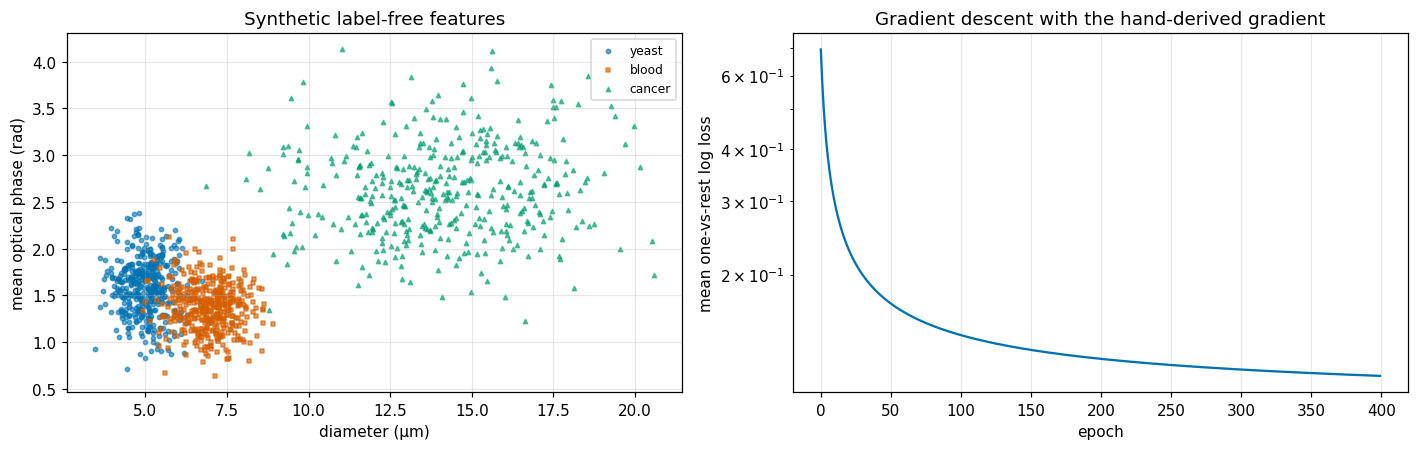

Figure: left, three clusters by diameter and phase: yeast small and low phase (circles), blood slightly larger with similar phase (squares), cancer cells large with high phase (triangles); yeast and blood overlap most. Right, the training loss falls steadily on a log scale.


In [9]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.2))
mk = ['o', 's', '^']
for c, n_ in enumerate(names):
    sel = y == c
    ax[0].scatter(X[sel, 0], X[sel, 1], s=8, marker=mk[c], alpha=0.6, label=n_)
ax[0].set_xlabel('diameter (µm)'); ax[0].set_ylabel('mean optical phase (rad)'); ax[0].legend(fontsize=8)
ax[0].set_title('Synthetic label-free features')
ax[1].plot(hist, '-'); ax[1].set_xlabel('epoch'); ax[1].set_ylabel('mean one-vs-rest log loss'); ax[1].set_yscale('log')
ax[1].set_title('Gradient descent with the hand-derived gradient')
plt.tight_layout(); plt.show()
print('Figure: left, three clusters by diameter and phase: yeast small and low phase (circles), blood slightly '
      'larger with similar phase (squares), cancer cells large with high phase (triangles); yeast and blood overlap '
      'most. Right, the training loss falls steadily on a log scale.')

---
## 7. What to take away

- **Chemistry and biophysics** give two contrasts: absorption (Beer-Lambert, weak in the near-IR) and phase ($\propto (n_{cell}-n_m)h$), and the phase integral is literally the cell's **dry mass**.
- **The instrument is a composite function.** The chain rule turns it into a product of stage derivatives: that predicts sensitivity (bias at quadrature) and propagates error bars (radius errors triple in mass).
- **Training a classifier is the chain rule again:** $(p - y)\,x$, checked against finite differences to $10^{-9}$-ish.
- **Computer engineering is the bottleneck:** tens of millions of lines per second means real-time ADCs, FPGAs/GPUs and compact models. That's where CE students fit in biophotonics.

**Honest limits:** single-pixel physics, synthetic features with made-up but plausible spreads, no real cells. Real pipelines also handle illumination drift, focus, overlapping cells and class imbalance.

## References

[1] K. Goda, K. K. Tsia, and B. Jalali, "Serial time-encoded amplified imaging for real-time observation of fast dynamic phenomena," *Nature*, vol. 458, no. 7242, pp. 1145–1149, 2009, doi: 10.1038/nature07980.

[2] C. L. Chen, A. Mahjoubfar, L.-C. Tai, I. K. Blaby, A. Huang, K. R. Niazi, and B. Jalali, "Deep learning in label-free cell classification," *Sci. Rep.*, vol. 6, art. 21471, 2016, doi: 10.1038/srep21471.

[3] G. Popescu, *Quantitative Phase Imaging of Cells and Tissues*. New York, NY, USA: McGraw-Hill, 2011.

[4] R. Barer, "Interference microscopy and mass determination," *Nature*, vol. 169, pp. 366–367, 1952.

*Reference details were written from memory; verify before citing.*